In [35]:
import open3d as o3d
import numpy as np
import copy
import time
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

def draw_registration_result(source, target, transformation):
    source_temp = copy.deepcopy(source)
    target_temp = copy.deepcopy(target)
    source_temp.paint_uniform_color([1, 0.706, 0])
    target_temp.paint_uniform_color([0, 0.651, 0.929])
    source_temp.transform(transformation)
    o3d.visualization.draw_geometries([source_temp, target_temp])

def convert2pc(cloud):
    temp = o3d.geometry.PointCloud()
    for point in cloud:
        temp.points.append(point.reshape(3,1))
    return temp

def convert2pc2(cloud, normal):
    temp = o3d.geometry.PointCloud()
    for point in cloud:
        temp.points.append(point.reshape(3,1))
    for norm in normal:
        temp.normals.append(norm.reshape(3,1))
    return temp

class MplColorHelper:

  def __init__(self, cmap_name, start_val, stop_val):
    self.cmap_name = cmap_name
    #self.cmap = plt.get_cmap(cmap_name)
    self.cmap=my_cmap
    self.norm = mpl.colors.Normalize(vmin=start_val, vmax=stop_val)
    self.scalarMap = cm.ScalarMappable(norm=self.norm, cmap=self.cmap)

  def get_rgb(self, val):
    return self.scalarMap.to_rgba(val)

In [36]:
# 1. lépés: olvassuk be a mesheket

template_mesh = o3d.io.read_triangle_mesh("x:/12/idealis_a3.ply")
object_mesh = o3d.io.read_triangle_mesh("x:/12/amk_a3C.ply")

template_mesh.compute_vertex_normals()
object_mesh.compute_vertex_normals()

TriangleMesh with 20 points and 36 triangles.

In [37]:
o3d.visualization.draw_geometries([template_mesh, object_mesh])

[Open3D WARNING] GLFW Error: WGL: Failed to make context current: A kért transzformációs művelet nem támogatott. 


In [38]:
%%time

# 2. lépés: mintavételezzük a mesheket, hogy egyforma sűrűségű részeket kapjunk

#template_cloud = template_mesh.sample_points_poisson_disk(number_of_points=50, init_factor=4)
#object_cloud = object_mesh.sample_points_poisson_disk(number_of_points=50, init_factor=4) # lassubb

template_cloud = template_mesh.sample_points_uniformly(number_of_points=250000) #kevésbé szép de gyors
object_cloud = object_mesh.sample_points_uniformly(number_of_points=250000)
o3d.visualization.draw_geometries([object_cloud])

print(len(np.asarray(object_cloud.points)))

[Open3D WARNING] GLFW Error: WGL: Failed to make context current: A kért transzformációs művelet nem támogatott. 
250000
Wall time: 4.6 s


In [8]:
#o3d.io.write_point_cloud("c:/users/dell/3mmvarratu/02vas.pcd", template_cloud)
#o3d.io.write_point_cloud("c:/users/dell/3mmvarratu/a5vn.pcd", object_cloud)

In [5]:
%%time

# 3. lépés: feature-alapú regisztráció: feature kiszámítása

template_pcr = np.mean(template_cloud.compute_nearest_neighbor_distance())
object_pcr = np.mean(object_cloud.compute_nearest_neighbor_distance())
pcr = (template_pcr + object_pcr)/2
 
template_cloud_fpfh = o3d.pipelines.registration.compute_fpfh_feature(
    template_cloud,
    o3d.geometry.KDTreeSearchParamHybrid(radius=pcr * 10, max_nn=1000))

object_cloud_fpfh = o3d.pipelines.registration.compute_fpfh_feature(
    object_cloud,
    o3d.geometry.KDTreeSearchParamHybrid(radius=pcr * 10, max_nn=1000))


Wall time: 3min 7s


In [6]:
%%time

# 3. lépés: feature-alapú regisztráció: regisztráció

distance_threshold = pcr*10

result = o3d.pipelines.registration.registration_fgr_based_on_feature_matching(
        template_cloud, object_cloud, template_cloud_fpfh, object_cloud_fpfh,
        o3d.pipelines.registration.FastGlobalRegistrationOption(
            maximum_correspondence_distance=distance_threshold, 
            iteration_number=500,
            maximum_tuple_count=2500))

print(result)
draw_registration_result(template_cloud, object_cloud, result.transformation)

RegistrationResult with fitness=8.588240e-01, inlier_rmse=1.558863e-02, and correspondence_set size of 214706
Access transformation to get result.
Wall time: 2min 4s


In [7]:
%%time

# 4. lépés: iteartív regisztráció

icp_distance_threshold = pcr*10

icp_result = o3d.pipelines.registration.registration_icp(
        template_cloud, object_cloud, icp_distance_threshold, result.transformation,
        o3d.pipelines.registration.TransformationEstimationPointToPlane(),
        o3d.pipelines.registration.ICPConvergenceCriteria(max_iteration=2000))

print(icp_result)
draw_registration_result(template_cloud, object_cloud, icp_result.transformation)

RegistrationResult with fitness=9.126200e-01, inlier_rmse=5.131153e-03, and correspondence_set size of 228155
Access transformation to get result.
Wall time: 4.96 s


In [30]:
draw_registration_result(template_cloud, object_cloud, icp_result.transformation)

In [31]:
o3d.visualization.draw_geometries([object_cloud])

In [8]:
%%time

#5. lépés: a távolságok kiszámítása

template_cloud_temp = copy.deepcopy(template_cloud)
template_cloud_temp.transform(icp_result.transformation)

dists = object_cloud.compute_point_cloud_distance(template_cloud_temp)

Wall time: 300 ms


4.3579513348798085e-05
0.21602774551377327


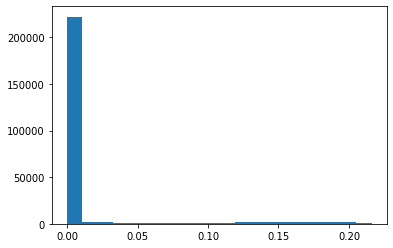

In [9]:
print(min(dists))
print(max(dists))

plt.hist(dists, bins=20)
plt.show()

In [10]:
print(max(dists))



0.21602774551377327


In [11]:
max(dists)*25              # max távolság mm-ben


5.4006936378443315

In [12]:
%%time

# 6. lépés: colormap vizualizáció

my_cmap = mpl.colors.LinearSegmentedColormap.from_list("", ["green","yellow","red"])

import numpy as np

COL = MplColorHelper('autumn_r', min(dists), np.percentile(dists, 95))

cols = []
for d in dists:
    cols.append(COL.get_rgb(d))
np_colors = np.array(cols)

object_cloud.colors = o3d.utility.Vector3dVector(np_colors[:,:3])

o3d.visualization.draw_geometries([object_cloud])

Wall time: 52.1 s


In [13]:
np.percentile(dists, 90)

0.03261187500658073

In [14]:
%%time

## 7. lépés: jelöljük meg egy bizonyos hátárérték fölötti pontokat

kuszob = np.percentile(dists, 90)  #minél nagyobb lehet, kis hiba kimutatásához
counter = 0
outliers = []
outliers_normals = []
complementer = []
complementer_normals = []
object_cloud.paint_uniform_color([1, 0.706, 0])

for d in dists:
    if d > kuszob:
        np_colors[counter] = [0.0,0.0,0.0,0.0]
        outliers.append(np.asarray(object_cloud.points)[counter])
        outliers_normals.append(np.asarray(object_cloud.normals)[counter])
    else:
        np_colors[counter] = [1, 0.706, 0, 0]
        complementer.append(np.asarray(object_cloud.points)[counter])
        complementer_normals.append(np.asarray(object_cloud.normals)[counter])
    counter+=1

object_cloud.colors = o3d.utility.Vector3dVector(np_colors[:,:3])
np_outliers = np.array(outliers)
np_outliers_normals = np.array(outliers_normals)

o3d.visualization.draw_geometries([object_cloud])

#new_pcr = np.average(object_cloud.compute_nearest_neighbor_distance()) #0.39

Wall time: 8.15 s


In [21]:
%%time

## 8. lépés: klaszterezük a kiugró részeket DBSCAN használatával #nem távolság alapu kell..
#sűrűség alapu klaszterezés, egy kupacban lévőket vizsgálja, o3d-ben ez van alapbol
cluster_count_threshold = 400   # minél kisebb a szám annál érzékenyebb
selected_cluster_ind = []

outlier_cloud = convert2pc2(np_outliers, np_outliers_normals)
comp_cloud = convert2pc2(np.asarray(complementer), np.asarray(complementer_normals))
comp_cloud.paint_uniform_color([1, 0.706, 0])

#o3d.visualization.draw_geometries([outlier_cloud])

dbscan_res = outlier_cloud.cluster_dbscan(pcr*15, 100) #sűrűség alapu klaszterezés, 
print(len(np.unique(dbscan_res)))

uni = np.unique(dbscan_res)
cluster_clouds = []
cluster_ind = 0
for u in uni: # végigmegyünk az egyedi klasztereken a kiugrók kivételével
    if u != -1:
        np_temp = np.asarray(outlier_cloud.points)[dbscan_res==u]
        np_temp_normals = np.asarray(outlier_cloud.normals)[dbscan_res==u]
        temp = convert2pc2(np_temp, np_temp_normals)
        if(len(np_temp) > cluster_count_threshold):
            selected_cluster_ind.append(cluster_ind)
            temp.paint_uniform_color([0,0,0])
        else:
            temp.paint_uniform_color([1, 0.706, 0])
        cluster_clouds.append(temp)
    cluster_ind += 1
        
i = 0
dbscan_cols = []
for p in np.asarray(outlier_cloud.points):
    c = cm.tab20(dbscan_res[i]+1)
    dbscan_cols.append(c)
    i+=1

outlier_cloud.colors = o3d.utility.Vector3dVector(np.asarray(dbscan_cols)[:,:3])
o3d.visualization.draw_geometries([outlier_cloud, comp_cloud])

1
Wall time: 1min 36s


In [16]:
cluster_clouds.append(comp_cloud)
o3d.visualization.draw_geometries(cluster_clouds)

selected_cluster_ind

In [17]:
np.asarray(cluster_clouds)[0]

PointCloud with 25000 points.

In [18]:
worst_cluster_cloud = np.asarray(cluster_clouds)[selected_cluster_ind][0]

In [19]:
powerof2 = lambda x: x * 2

error_dists = np.array(worst_cluster_cloud.compute_point_cloud_distance(template_cloud))
rmse = np.sqrt(np.sum(powerof2(error_dists))/len(error_dists))
rmse


0.5106526948711488

In [20]:
rmse*25


12.76631737177872

In [30]:
sump = np.array([0,0,0])
for p in np.asarray(worst_cluster_cloud.points):
    sump = sump + p
meanp = sump/len(np.asarray(worst_cluster_cloud.points))
meanp



array([ 0.31658691, -0.00076077,  0.32699883])

In [39]:
worst_cluster_cloud.translate([np.asarray(worst_cluster_cloud.points)[:,0].min(), \
                             np.asarray(worst_cluster_cloud.points)[:,1].min(), \
                             np.asarray(worst_cluster_cloud.points)[:,2].min()])



PointCloud with 25000 points.